In [1]:
import optuna
import pandas as pd
import seaborn as sns
from sklearn.metrics import f1_score
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.preprocessing import StandardScaler , OneHotEncoder

In [2]:
data = pd.read_csv('heart.csv')

In [3]:
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
data.shape

(918, 12)

In [5]:
data.nunique()

Age                50
Sex                 2
ChestPainType       4
RestingBP          67
Cholesterol       222
FastingBS           2
RestingECG          3
MaxHR             119
ExerciseAngina      2
Oldpeak            53
ST_Slope            3
HeartDisease        2
dtype: int64

In [6]:
data.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [7]:
data.duplicated().sum()

np.int64(0)

<Axes: xlabel='MaxHR', ylabel='Count'>

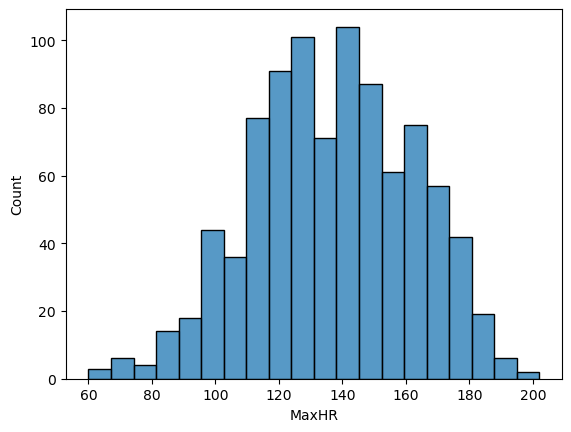

In [8]:
sns.histplot(data['MaxHR'] )

<Axes: xlabel='Age', ylabel='Count'>

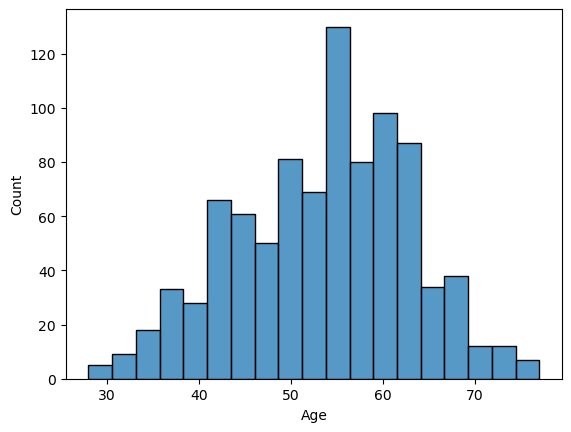

In [9]:
sns.histplot(data['Age'] )


In [10]:
data['Age'].max()

77

In [11]:
y = data['HeartDisease']
x = data.drop('HeartDisease' , axis = 1)
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size=0.2 , random_state=42)

In [12]:
data.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [14]:
scl_cols = [col for col in x_train.select_dtypes(['int64', 'float64']).columns if x_train[col].nunique() != 2]
obj_cols = [col for col in x_train.select_dtypes(['object']).columns]

In [15]:
pipe = ColumnTransformer(
    transformers=[
        ('object' , OneHotEncoder(drop='if_binary') , obj_cols),
        ('scalled' , StandardScaler() , scl_cols)
    ] , remainder='passthrough'
)

In [16]:
x_train = pipe.fit_transform(x_train)
x_test = pipe.transform(x_test)

In [17]:
estimators = [
    ('dec_tree' , DecisionTreeClassifier(random_state=42)),
    ('knn' , KNeighborsClassifier()),
    ('log_reg' , LogisticRegression())
]

In [18]:
stack_reg =StackingClassifier(
    estimators=estimators,
    cv=5
)

In [19]:
stack_reg.fit(x_train,y_train)
pred = stack_reg.predict(x_test)
print(f1_score(y_test , pred))

0.8899521531100478


In [20]:
# 1. Define the core objective function
def objective(trial):
    X, y = x_train , y_train
    
    # 2. Define the hyperparameter search space (the "Suggestions")
    max_depth = trial.suggest_int('max_depth', 3, 20)

    # 3. Instantiate the model with chosen hyperparameter variants
    clf = DecisionTreeClassifier(
        max_depth=max_depth,
        random_state=42
    )
    
    # 4. Evaluate using Cross-Validation
    score = cross_val_score(clf, X, y, cv=3, scoring='f1_macro').mean()    
    # Return the metric to be minimized or maximized
    return score

if __name__ == '__main__':
    # 5. Create a study session targeting maximum accuracy
    study = optuna.create_study(direction='maximize')
    
    # 6. Execute the Bayesian optimization loop
    study.optimize(objective, n_trials=30 , n_jobs=-1)
    
    # 7. Print out results
    print(f"Optimal Hyperparameters: {study.best_params}")
    print(f"Highest Achieved Score: {study.best_value:.4f}")

[I 2026-07-22 20:20:51,865] A new study created in memory with name: no-name-2e86e52b-9699-4f44-a75d-9f2e6a1979c5
[I 2026-07-22 20:20:52,052] Trial 0 finished with value: 0.7813502245099536 and parameters: {'max_depth': 20}. Best is trial 0 with value: 0.7813502245099536.
[I 2026-07-22 20:20:52,056] Trial 4 finished with value: 0.7857075345736501 and parameters: {'max_depth': 7}. Best is trial 4 with value: 0.7857075345736501.
[I 2026-07-22 20:20:52,070] Trial 1 finished with value: 0.7813502245099536 and parameters: {'max_depth': 16}. Best is trial 4 with value: 0.7857075345736501.
[I 2026-07-22 20:20:52,096] Trial 2 finished with value: 0.7813502245099536 and parameters: {'max_depth': 17}. Best is trial 4 with value: 0.7857075345736501.
[I 2026-07-22 20:20:52,099] Trial 6 finished with value: 0.7813502245099536 and parameters: {'max_depth': 15}. Best is trial 4 with value: 0.7857075345736501.
[I 2026-07-22 20:20:52,100] Trial 3 finished with value: 0.8070207580491737 and parameters: 

Optimal Hyperparameters: {'max_depth': 3}
Highest Achieved Score: 0.8193


In [21]:
# Plots parameter search progression over time
optuna.visualization.plot_optimization_history(study).show()

In [ ]:
# Evaluates which hyperparameters impact scores the most
optuna.visualization.plot_param_importances(study).show()

will be usefull if there is multiple parameters optimized beside the max_depth